In [1]:
import os
import re
import glob
import time
import das2
import numpy as np
import datetime as dt
import matplotlib.pyplot as plt

from matplotlib.ticker import AutoMinorLocator

from JunoPy.mag import MagData
from JunoPy.waves import WavesDataDas
from JunoPy.library import find_ticks_between

In [2]:
start = dt.datetime.strptime('2017-338T01:49:57', '%Y-%jT%H:%M:%S') - dt.timedelta(minutes=10)
end   = dt.datetime.strptime('2017-338T01:51:00', '%Y-%jT%H:%M:%S') + dt.timedelta(minutes=10)

wavesdata = WavesDataDas(start, end)

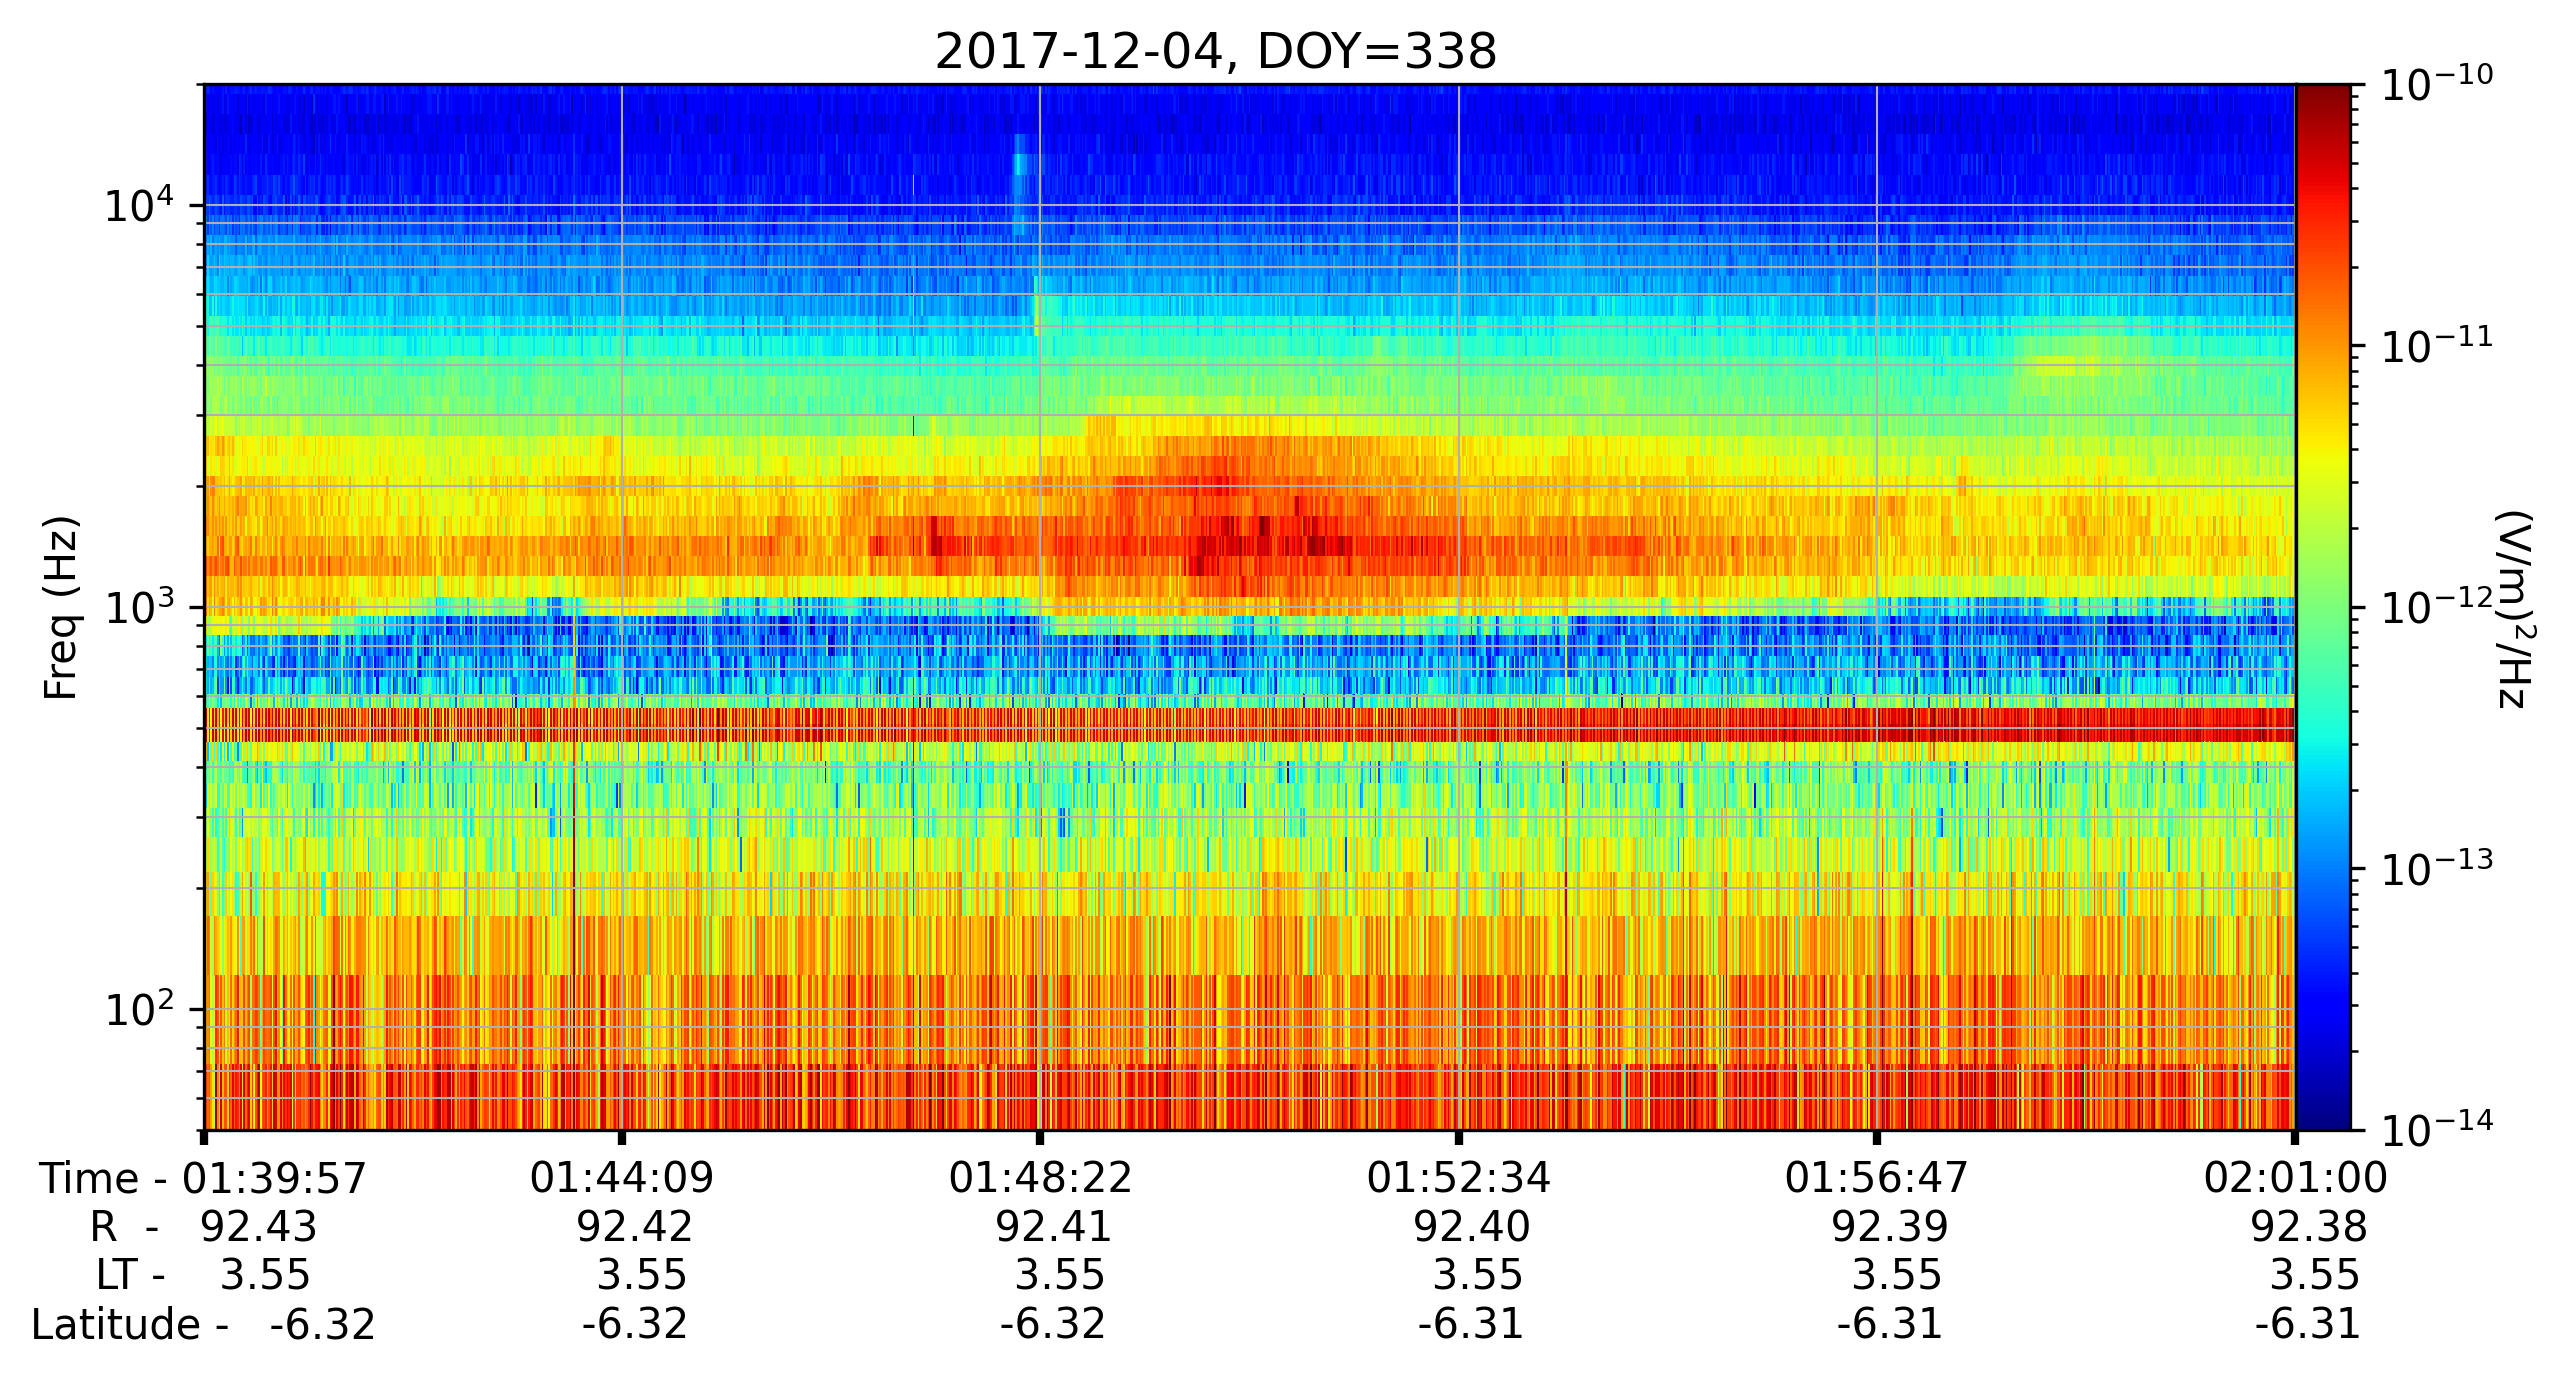

In [3]:
def plot_waves_data(wavesdata, start, end):
    """Plot data between start and end."""
    
    # Find the ticks.
    timearray, tickstring = find_ticks_between(start, end)
    
    # Create the figure.
    fig, axs = plt.subplots(1, 1, 
                            gridspec_kw={'hspace': 0, 'right':0.9, 'top':0.9}, 
                            figsize=(9, 4.5), 
                            dpi=300)
    
    axs = wavesdata.plot(axs, freqlimit=True, vmin=1e-14, vmax=1e-10)
    
    # a.set_xlim([timearray[0], timearray[-1]])
    axs.set_xticks(timearray)
    axs.set_xticklabels(tickstring)
    axs.label_outer()
        
    axs.grid(zorder=2, which='both', lw=0.5)
    
    # axs.set_ylim([4e5, 3e7])

    # axs.axvspan(start + dt.timedelta(minutes=15), 
    #             end - dt.timedelta(minutes=15), alpha=0.2, color='red')
            
    axs.tick_params(axis='x', width=2, rotation=0)
    axs.xaxis.label.set_visible(False)
    
    plt.suptitle(dt.datetime.strftime(start, '%Y-%m-%d') + \
                 ', DOY={:s}'.format(dt.datetime.strftime(start, '%j')), y=0.94)
    
    # fig.savefig('out_waves_selected/' + dt.datetime.strftime(start, '%Y-%jT%H:%M_waves_2') + '.png')
    # plt.close(fig)
    
plot_waves_data(wavesdata, start, end)